# 3. First OD solution

> Fit a week of simulated DSN tracking with a batch filter, check the solution against the truth, and predict where OSIRIS-REx will be when DSS-35 acquires it on June 8.
>
> ⏱ ~15 min &nbsp;·&nbsp; **Prereqs:** 2. Tracking data &nbsp;·&nbsp; **Uses:** `outputs/01_scenario_and_truth/truth.bsp`, `outputs/02_tracking_data/*.json` &nbsp;·&nbsp; **Produces:** `outputs/03_first_od_solution/solution.json` &nbsp;·&nbsp; **Next:** 4. Validating a model

**The question for this series.** The simulated tracking ends at midnight on June 7. Six hours later, at 05:55 UTC on June 8, the Canberra antenna DSS-35 acquires OSIRIS-REx for a real tracking pass (chapter 8). *Given a week of tracking, how well do we know where the spacecraft will be at that moment?* This chapter gives the first answer. Every later chapter changes the filter or the data and reports the same numbers, so you can see what each change buys.

<div style="border-left:4px solid #9333ea; background:rgba(147,51,234,0.12); padding:6px 10px; border-radius:4px">
🟣 <b>QUESTION:</b> v3 prototype. Chapters 1 and 2 of this version are not written yet: run <code>python prepare.py</code> in <code>tutorials/v3/</code> once to create their outputs (about 2 s). Compare with <code>v2/06_first_od_solution.ipynb</code>.
</div>

## Setup

The scenario from chapters 1–2 comes from `scenario.py`: units, the arc, the truth spacecraft and the six measurement models. The setup only loads what those chapters wrote: the truth trajectory and the tracking files.

In [1]:
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scarabaeus as scb

from scenario import (
    km, m, sec, day, J2000, SUN, # units, frame, central body
    data_epochs, t_pass,         # the tracking arc and the June 8 prediction epoch (ch. 1)
    orex_truth, PLANETS,         # the truth spacecraft and its third bodies (ch. 1)
    MASS, SRP_AREA, CR,          # spacecraft properties (ch. 1)
    models,                      # range and range-rate from DSS-14/43/63 (ch. 2)
)

out = Path("outputs/03_first_od_solution")
shutil.rmtree(out, ignore_errors=True)
out.mkdir(parents=True)

# Starting here? `python prepare.py` creates the outputs of chapters 1 and 2.
scb.SpiceManager.load_kernel("outputs/01_scenario_and_truth/truth.bsp")  # truth (ch. 1)
tracking = scb.MeasurementSpec.many(*[                                    # tracking data (ch. 2)
    scb.MeasurementSpec(
        model=model,
        dataset_name=model.name,
        observed_meas=model.observed_measurements(
            f"outputs/02_tracking_data/{model.name.replace(' ', '_')}.json", units=model.sigma.units
        ),
    )
    for model in models
])

n_obs = sum(spec["observed_meas"].meas_time_et.size for spec in tracking)
print(f"{len(tracking)} datasets, {n_obs} observations, {data_epochs[0].to(rep='ISOC')} to {data_epochs[-1].to(rep='ISOC')}")

6 datasets, 632 observations, 2018-06-01T00:01:09.1849 (TDB) to 2018-06-07T23:31:09.1849 (TDB)


`MeasurementSpec` pairs each measurement model with its observations; `MeasurementSpec.many` collects them into the filter's input. The filter computes residuals and partials from these models at every iteration (chapter 4 shows how).

## 1. The filter's starting point

The filter never sees the truth. It starts from an **a-priori state**, in operations the previous orbit determination solution, and an **a-priori covariance** describing how wrong that state may be. Here the a-priori is the true initial state plus a known error of 10 km and 1 cm/s per axis, so the result can be checked later. The covariance is deliberately loose (100 km, 0.1 m/s per axis) so the solution is driven by the data:

In [2]:
orex_reference = scb.Spacecraft("OREx reference", -64001, MASS, SRP_AREA, CR)  # same properties as the truth

x0_truth = orex_truth.get_state(data_epochs[0], reference_frame="J2000", origin="SUN").quantity
r_apriori = x0_truth[:3] + scb.ArrayWUnits([10.0] * 3, km)
v_apriori = x0_truth[3:] + scb.ArrayWUnits([0.01] * 3, m / sec).convert_to(km / sec)

apriori_state = (
    scb.StateDefinition()
    .position(orex_reference, scb.ArrayWFrame(r_apriori, J2000))
    .velocity(orex_reference, scb.ArrayWFrame(v_apriori, J2000))
)
P0 = scb.CovarianceMatrix(
    [scb.ArrayWUnits(100.0, km)] * 3 + [scb.ArrayWUnits(0.1, m / sec).convert_to(km / sec)] * 3,
    data_epochs[0],
    from_list=True,
)

The filter's spacecraft, `orex_reference`, is a copy of the truth with its own SPICE ID. The filter writes its reference trajectory to an SPK at every iteration, and the measurement models look states up through SPICE, so the reference and the truth must not share an ID. Its physical properties match the truth's, so the filter's dynamics model is exact here; chapter 6 breaks that on purpose.

The **reference propagator** integrates the a-priori state and its state transition matrix over the arc, with the same force model as the truth. The filter linearizes about this trajectory:

In [3]:
propagator = scb.Propagator(
    primary_body=orex_reference,
    state_vector=scb.StateArray(epoch=data_epochs[0], origin=SUN, state=apriori_state),
    tspan=data_epochs,
    force_models=scb.ForceModelTranslation(orex_reference, third_bodies=PLANETS, cannonball_SRP=True),
)

→ *Fundamentals: Defining a state* (the `estimation` / `dynamics` flags, and parameters beyond position and velocity)

## 2. The fit

`SRIFB` is the batch square-root information filter: it maps every observation to the initial epoch through the STM, solves the weighted least-squares problem for the correction $\delta x_0$ with orthogonal transformations, and re-propagates the reference. `fit()` repeats this until a convergence test passes. `LSB`, the normal-equations batch filter, has the same interface (section 6).

In [4]:
%%capture fit_log
# 🔵 TODO: remove %%capture once the measurement models stop printing progress (PLAN.md, API change 1)
settings = scb.FilterSettings(
    initial_covariance=P0,
    output=scb.OutputSettings(metadata={"scenario": "OSIRIS-REx approach, June 1-8 2018", "chapter": 3}),
)
srifb = scb.SRIFB(propagator=propagator, measurements=tracking, settings=settings,
                  traj_name="reference.bsp", traj_dir=str(out), verbose=False)
solution, n_iterations, converged = srifb.fit(verbose=False)

In [5]:
print(f"Converged: {converged} after {n_iterations} iterations\n")
solution.print_stats()

Converged: True after 2 iterations

ORBIT DETERMINATION SOLUTION STATISTICS

Solution Overview:
  Number of epochs:        270
  Number of states:        6
  Covariance analysis:     False

Chi-Squared Test:
  Chi-squared value:       600.0735
  Degrees of freedom:      626
  Normalized chi-squared:  0.9586
  Status:                  Filter appears well-tuned

Covariance Information:
  Initial position uncertainty (1σ):
    X: 7.540777e-01 km
    Y: 9.212231e-01 km
    Z: 1.017740e+00 km
    RSS: 1.566231e+00 km
  Final position uncertainty (1σ):
    X: 8.402855e-01 km
    Y: 9.462019e-01 km
    Z: 1.125326e+00 km
    RSS: 1.693439e+00 km
  Initial velocity uncertainty (1σ):
    VX: 3.017435e-07 km/s
    VY: 1.175928e-06 km/s
    VZ: 9.514246e-07 km/s
    RSS: 1.542422e-06 km/s
  Final velocity uncertainty (1σ):
    VX: 2.921283e-07 km/s
    VY: 1.175687e-06 km/s
    VZ: 9.518281e-07 km/s
    RSS: 1.540635e-06 km/s


Two iterations: the first removes almost all of the 17 km / 1.7 cm/s a-priori error, because the problem is nearly linear at this scale (chapter 4 checks this), and the second corrects the remaining ~2 cm. `fit()` stops when the RMS of the correction falls below `convergence_threshold` (default $10^{-5}$ in km and km/s) or when the weighted cost of the post-fit residuals stops changing; with the default `convergence_criterion="any"`, either test ends the iterations.

A normalized χ² close to 1 means the post-fit residuals are consistent with the measurement σ, as expected when the filter's models match those that generated the data.

## 3. Residuals

The post-fit residuals, normalized by each measurement's σ, should look like white noise inside ±3:

<div style="border-left:4px solid #2563eb; background:rgba(37,99,235,0.12); padding:6px 10px; border-radius:4px">
🔵 <b>TODO:</b> <code>Plotting.plot_postfits_scatter</code> can't draw these datasets: it classifies them by name (<code>"Range"</code>, <code>"Range Rate"</code>, case-sensitive) and expects one residual per solution epoch in every dataset. Hand-drawn until it can (PLAN.md, API change 9).
</div>

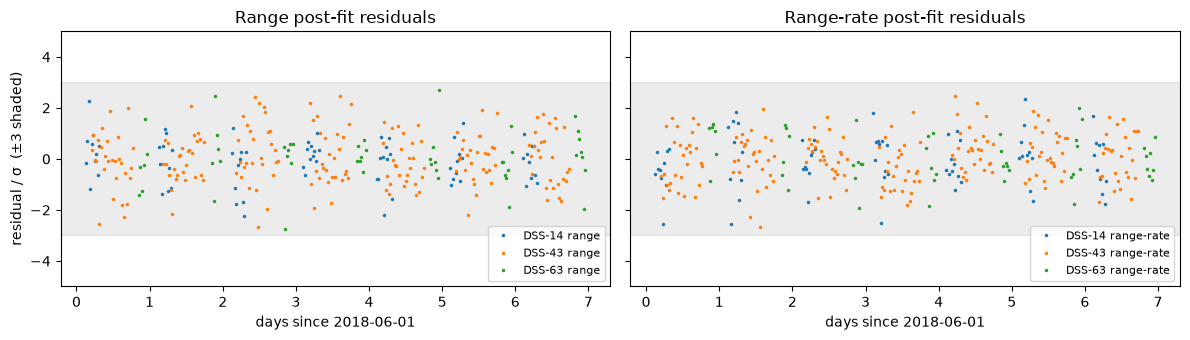

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for spec in tracking:
    residual, sigma = np.array(solution.postfits[spec["dataset_name"]]).T  # [residual, σ] per observation
    t_days = (spec["observed_meas"].meas_time_et - data_epochs[0]).convert_to(day).values
    panel = ax[0] if type(spec["model"]) is scb.RangeIdeal else ax[1]
    panel.plot(t_days, residual / sigma, ".", ms=3, label=spec["dataset_name"])
for panel, title in zip(ax, ["Range", "Range-rate"]):
    panel.axhspan(-3, 3, color="gray", alpha=0.15)
    panel.set(title=f"{title} post-fit residuals", xlabel="days since 2018-06-01", ylim=(-5, 5))
    panel.legend(fontsize=8, loc="lower right")
ax[0].set_ylabel("residual / σ  (±3 shaded)")
plt.tight_layout()

## 4. Errors against the truth

Because the data are simulated, the estimate can be compared with the truth. `Trajectory` reads the truth back from its SPK, and `Plotting.plot_state_errors` draws the estimation error of each component against the filter's own 1, 2 and 3σ bounds:

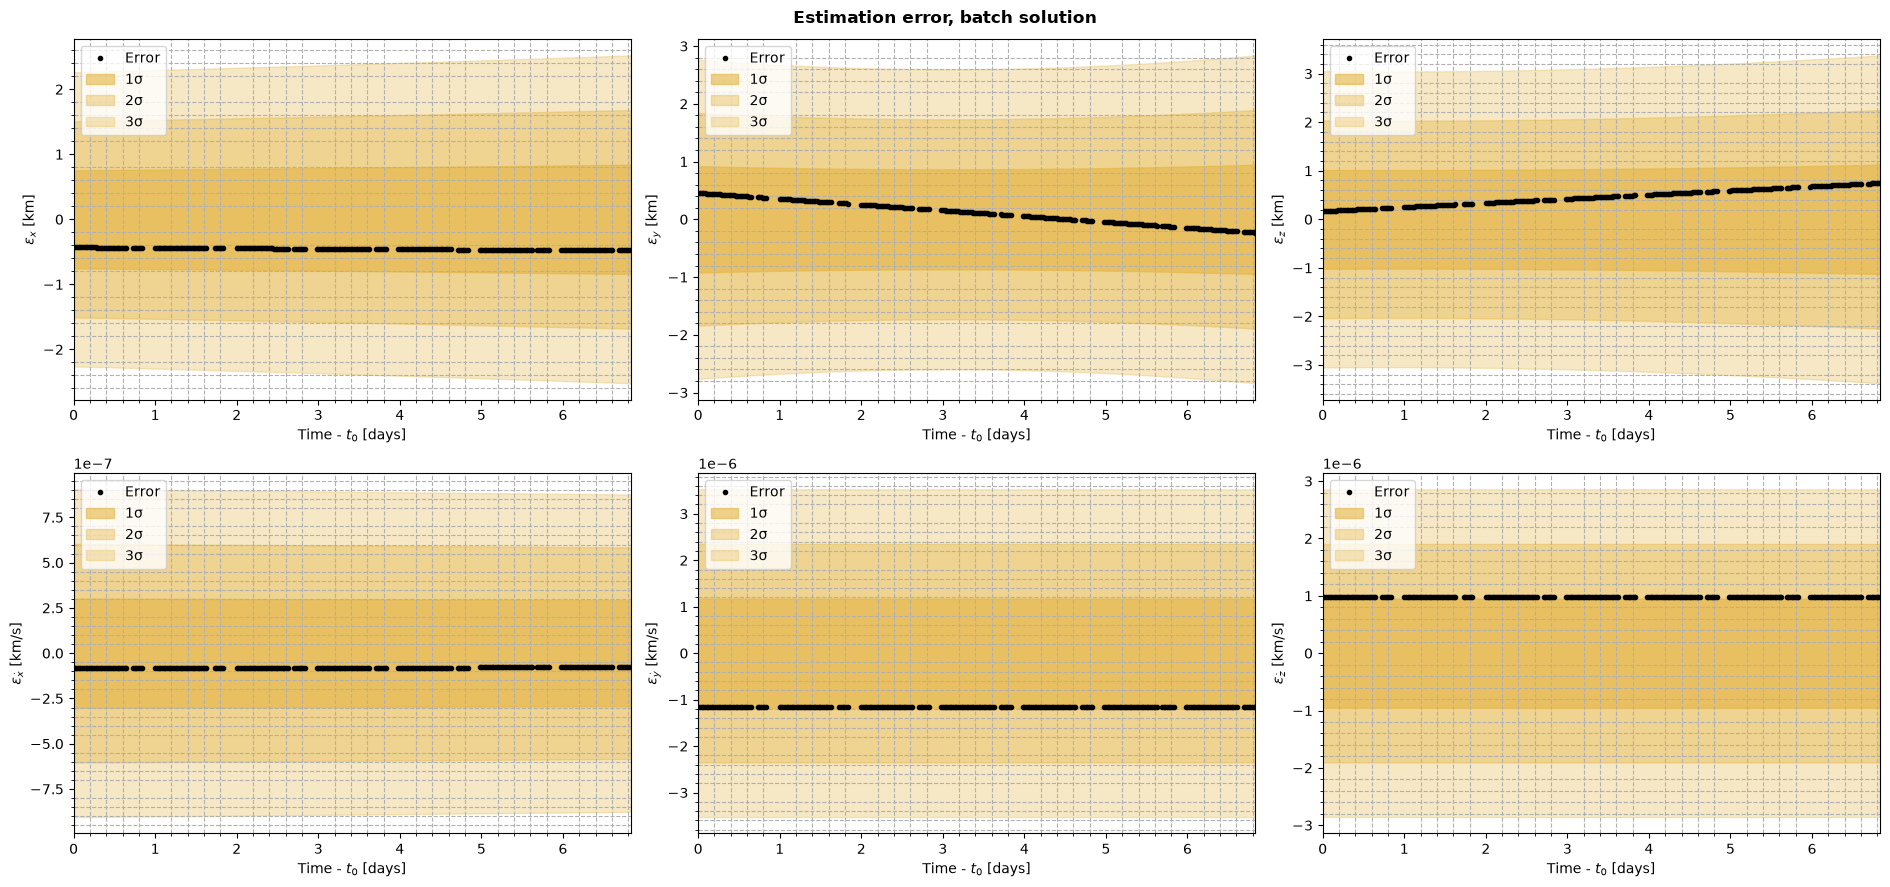

In [7]:
truth = scb.Trajectory(ref_frame=J2000, origin=SUN, body=orex_truth)  # read from the truth SPK
t_solution = scb.EpochArray(solution.timestamps, sys="TDB")           # the measurement epochs

fig = scb.Plotting.plot_state_errors(solution, truth, t_solution, n_sigma=3, title="Estimation error, batch solution")

Every component stays within about 1σ: the covariance is an honest description of the actual error. Over one week of a heliocentric orbit, gravity barely changes an error, so the velocity error is nearly constant and the position error grows linearly at that rate. The whole curve is one initial-state error carried forward by the dynamics; its sign and size come from this noise realization.

## 5. The shape of the uncertainty

A position uncertainty of about 1 km per axis may seem large for 2 m range data. The covariance is far from round: two-way range measures the distance along the Earth–spacecraft line of sight directly, while the position across it (the *plane of sky*) is inferred only indirectly, through the dynamics and the daily signature of Earth's rotation in the range-rate. Projecting the covariance at the end of the arc:

In [8]:
P_end = solution.propagate_covariance(data_epochs[-1:])[0]
los = orex_truth.get_state(data_epochs[-1], reference_frame="J2000", origin="EARTH").quantity.values[:3]
u = los / np.linalg.norm(los)

sigma_los = np.sqrt(u @ P_end[:3, :3] @ u)
sigma_sky = np.sqrt(np.trace(P_end[:3, :3]) - sigma_los**2)
print(f"1σ along the line of sight: {sigma_los * 1e3:6.2f} m")
print(f"1σ in the plane of sky:     {sigma_sky:6.2f} km (RSS of the two transverse directions)")

1σ along the line of sight:   0.45 m
1σ in the plane of sky:       1.69 km (RSS of the two transverse directions)


Under a meter along the line of sight, over a kilometer across it. This geometry is typical of Earth-based radiometric tracking of a distant spacecraft, and it is why missions add data types that measure the plane of sky directly, such as ΔDOR and optical navigation (*Model catalogs: Measurement types*).

## 6. Predicting the June 8 pass

`propagate_state_covariance` maps the estimate and its covariance to any epoch, including epochs after the data arc. At the start of the DSS-35 pass:

In [9]:
state_pass, P_pass = solution.propagate_state_covariance(t_pass)[0]

x_true = orex_truth.get_state(t_pass, reference_frame="J2000", origin="SUN").quantity.values
error = state_pass.values0.values - x_true
los = orex_truth.get_state(t_pass, reference_frame="J2000", origin="EARTH").quantity.values[:3]
u = los / np.linalg.norm(los)  # Earth-spacecraft direction

position_error, position_sigma = np.linalg.norm(error[:3]), np.sqrt(np.trace(P_pass[:3, :3]))
print(f"Prediction for the start of the DSS-35 pass, {t_pass[0].to(rep='ISOC')}")
print(f"  position error              {position_error:7.2f} km")
print(f"  position 1σ (RSS)           {position_sigma:7.2f} km   error/σ = {position_error / position_sigma:.2f}")
print(f"  line-of-sight velocity 1σ   {np.sqrt(u @ P_pass[3:, 3:] @ u) * 1e6:7.3f} mm/s")

Prediction for the start of the DSS-35 pass, 2018-06-08T05:56:12.1847 (TDB)
  position error                 0.95 km
  position 1σ (RSS)              1.71 km   error/σ = 0.55
  line-of-sight velocity 1σ     0.074 mm/s


This is the **scoreboard** every later chapter reports:

| Chapter | Filter | Position error at the pass | 1σ | Error / σ |
|---|---|---|---|---|
| 3 | batch, exact dynamics | ~0.9 km | ~1.7 km | ~0.6 |

The prediction is consistent: the error is within 1σ. The line-of-sight velocity is known to well under 0.1 mm/s, which corresponds to a few mHz of two-way X-band Doppler, comparable to the noise of the real pass in chapter 8. That pass will be a genuine test of this prediction.

## 7. Saving the solution

`save` writes the solution, every iteration included, to one JSON file. Its metadata records the state definition, the a-priori, the convergence test and the provenance, so later chapters (and other tools) can read it without this notebook:

In [10]:
solution.save(out / "solution.json")

[SolutionOD] All iterations saved → outputs/03_first_od_solution/solution.json


[SolutionOD] Reference trajectory saved → outputs/03_first_od_solution/solution_reference.bsp
[SolutionOD] Estimated trajectory not saved: no estimated parameters in the state.


## 8. Switching the algorithm

The filters share one interface, so changing the estimator is a one-line change. A filter updates the propagator it is given (after `fit()` it holds the estimate), so a second run needs a fresh one; `scenario.py` provides `reference_propagator()` for that, built from exactly the a-priori above.

In [11]:
%%capture fit_log_lsb
from scenario import reference_propagator  # the propagator of section 1, freshly built

lsb = scb.LSB(propagator=reference_propagator(), measurements=tracking, settings=settings,
              traj_name="reference_lsb.bsp", traj_dir=str(out), verbose=False)
solution_lsb, _, _ = lsb.fit(verbose=False)

In [12]:
difference = solution_lsb.state_est[0] - solution.state_est[0]
print(f"LSB - SRIFB at the first epoch: {np.linalg.norm(difference[:3]) * 1e6:.0f} mm in position (1σ: about 1.6 km)")

LSB - SRIFB at the first epoch: 28 mm in position (1σ: about 1.6 km)


The two batch filters agree to a few centimeters, far inside the uncertainty: both stop as soon as the convergence test passes, a couple of centimeters short of the exact least-squares answer.

## Summary

| Concept | Scarabaeus API |
|---|---|
| Filter input | `MeasurementSpec(model, observed_meas, dataset_name)`, `MeasurementSpec.many` |
| A-priori | `StateDefinition` on a reference `Spacecraft` (own SPICE ID), `CovarianceMatrix(sigmas, epoch, from_list=True)` |
| Reference trajectory | `Propagator(...)` with the filter's force model |
| Batch filters | `SRIFB(propagator, measurements, settings)`, `LSB(...)`, `fit()` → `(solution, n_iterations, converged)` |
| Settings | `FilterSettings(initial_covariance=..., output=OutputSettings(metadata=...))` |
| Inspecting a solution | `print_stats()`, `Plotting.plot_postfits_scatter`, `Plotting.plot_state_errors` with a truth `Trajectory` |
| Covariance and state at any epoch | `propagate_covariance(epochs)`, `propagate_state_covariance(epochs)` |
| Saving | `SolutionOD.save(path)` |

The a-priori of section 1 is in `scenario.py` as `orex_reference`, `apriori_state`, `P0` and `reference_propagator()`; later chapters import it.

**Try it**

- Drop the range-rate datasets from `tracking` and refit. What happens to the line-of-sight velocity σ at the pass, and to the plane-of-sky σ?
- Tighten `P0` to 10 km and 1 cm/s per axis. Does the estimate change? Does the covariance at the pass?

**Next:** 4. Validating a model opens `fit()` up: the STM, the measurement partials and the linearized measurement equation it solves. To see the scoreboard move, jump to 6. When the dynamics are wrong.